# OP-FL v2 — 07. Confirmation d'OP-Cal sur le test verrouillé (96 hôpitaux, évaluation unique)

Ce notebook applique **sans aucun changement** la spécification gelée du 06c et l'amendement 1 validé du 06d. Avant de tourner, il vérifie leurs empreintes SHA-256, celles du texte de dépôt et celles des modules.

**Trois phases, dans cet ordre :**

| Phase | Étapes | Ce qui est lu des hôpitaux verrouillés |
|---|---|---|
| A0 — contrôles sur le développement | 2 | rien |
| A — modèles finaux et prédictions gelées | 3–4 | entrées (24 h), split train pour les descripteurs, nombres de dosages ; **aucun label, aucun résultat d'examen après 24 h** |
| B — ouverture et tests confirmatoires | 5 | labels (décès ; hyperlactatémie) |
| C — analyses descriptives | 6 | idem B |

* **Fin de la phase A.** Les prédictions (scores des modèles finaux, â_h d'OP-Cal, E1, terme mécanistique) sont enregistrées et leur empreinte est notée dans `journal_07.json` **avant** l'ouverture des labels.
* **Phase B.** Elle n'est exécutée qu'une fois : si `resultats_confirmatoires.json` existe déjà, ses résultats sont relus, pas recalculés.
* **Modèles finaux.** Réglages et seeds des notebooks 02 (mortalité : `x_only`, `grud`) et 05 (hyperlactatémie : `A_lac_neg_x_only`), entraînés sur les 60 hôpitaux de développement. Le meilleur round est choisi sur le `val` poolé de ces hôpitaux. L'entraînement peut reprendre là où il s'est arrêté.
* **Méta-modèle.** `SiteEB` ajusté **une fois** sur les a_h croisés des 60 hôpitaux de développement, avec les 44 descripteurs gelés.

**Critères confirmatoires (amendement 1)** : unilatéraux à 2,5 %, procédure graphique de Bretz et al. (2009). Poids initiaux C1a 1/2 et C4 1/2 ; arêtes C4 → C1a → C1b → C2 → C4.
* **C1a** : b > 0 (affirmation principale) ; REML et Knapp-Hartung.
* **C4** : score efficace pondéré, permutation exacte.
* **C1b** : b > 0,5.
* **C2** : gain de log-vraisemblance par patient contre E0.

## Étape 0 — Vérifications d'intégrité et configuration

In [6]:
# ============================================================
# ÉTAPE 0 — VÉRIFICATIONS D'INTÉGRITÉ ET CONFIGURATION
# ============================================================
import sys, os, json, re, time, hashlib, importlib, warnings
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import torch

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES02 = PROJECT_DIR / "results" / "02_baselines"
RES04 = PROJECT_DIR / "results" / "04_observation_label"
RES05 = PROJECT_DIR / "results" / "05_raccourci_masquage"
RES06B = PROJECT_DIR / "results" / "06b_faisabilite_opcal"
RES06C = PROJECT_DIR / "results" / "06c_robustesse_opcal"
RES06D = PROJECT_DIR / "results" / "06d_amendement_puissance"
RES_DIR = PROJECT_DIR / "results" / "07_confirmation"
PRED_DIR, FIG_DIR = RES_DIR / "preds", RES_DIR / "figures"
for d_ in (PRED_DIR, FIG_DIR):
    d_.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."
FOLDS = sorted(int(k) for k in protocol["folds"])
DEV = sorted(int(h) for k in protocol["folds"] for h in protocol["folds"][k])
LOCKED = sorted(int(h) for h in protocol["locked_test_hospitals"])

SPEC_PATH, AMEND_PATH, OSF_PATH = RES06C / "specification_gelee.json", RES06D / "amendement_1.json", RES06D / "depot_osf.md"
SPEC = json.loads(SPEC_PATH.read_text(encoding="utf-8"))
AMEND = json.loads(AMEND_PATH.read_text(encoding="utf-8"))
SPEC_SHA, AMEND_SHA = sha256(SPEC_PATH), sha256(AMEND_PATH)
OSF = OSF_PATH.read_text(encoding="utf-8")
INTEGRITE = {
    "spécification au statut « gelée »": SPEC["statut"] == "gelée",
    "amendement au statut « validé »": AMEND["statut"] == "validé",
    "amendement lié à la spécification": AMEND["specification"]["sha256"] == SPEC_SHA,
    "empreintes identiques à celles du texte de dépôt (commit)": SPEC_SHA in OSF and AMEND_SHA in OSF,
    **{f"module {f} inchangé": sha256(SRC_DIR / f) == h for f, h in AMEND["code_sha256"].items()},
}
for k, v in INTEGRITE.items():
    print(("OK     " if v else "ÉCHEC  ") + k)
assert all(INTEGRITE.values()), "Intégrité non vérifiée : le notebook 07 ne doit pas tourner."

cfg02 = json.loads((RES02 / "config.json").read_text(encoding="utf-8"))
cfg05 = json.loads((RES05 / "config.json").read_text(encoding="utf-8"))
cfg04 = json.loads((RES04 / "config.json").read_text(encoding="utf-8"))
CFG = cfg02["cfg"]
assert cfg05["cfg"] == CFG, "Réglages différents entre les notebooks 02 et 05."
SEEDS_M, SEEDS_L = [int(s) for s in cfg02["seeds"]], [int(s) for s in cfg05["seeds"]]
FROZEN = SPEC["meta_modele"]["descripteurs"]
K_CONF = int(SPEC["k_confirmatoire"])
N_BOOT, N_PERM, SEED = 2000, 2000, 2026
c4_text = next(c["test"] for c in AMEND["criteres"] if c["code"] == "C4")
TAU2_TEXT = float(re.search(r"τ² = ([0-9.]+) fixé", c4_text).group(1))
torch.set_num_threads(max(1, (os.cpu_count() or 2) - 1))

JOURNAL_PATH = RES_DIR / "journal_07.json"
JOURNAL = json.loads(JOURNAL_PATH.read_text(encoding="utf-8")) if JOURNAL_PATH.exists() else []
def journal(event, **kw):
    JOURNAL.append({"date": datetime.now().isoformat(timespec="seconds"), "evenement": event, **kw})
    JOURNAL_PATH.write_text(json.dumps(JOURNAL, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
journal("démarrage", spec_sha256=SPEC_SHA, amendement_sha256=AMEND_SHA)
print(f"\nProtocole {protocol['hash']} | {len(DEV)} hôpitaux de développement, {len(LOCKED)} verrouillés")
print(f"Mortalité : seeds {SEEDS_M} ; lactate : seeds {SEEDS_L} ; {CFG['rounds']} rounds | τ² de C4 (amendement) = {TAU2_TEXT}")

OK     spécification au statut « gelée »
OK     amendement au statut « validé »
OK     amendement lié à la spécification
OK     empreintes identiques à celles du texte de dépôt (commit)
OK     module opcal_feas.py inchangé
OK     module opcal_robust.py inchangé
OK     module opcal_amend.py inchangé

Protocole d92099ea7c11d517 | 60 hôpitaux de développement, 96 verrouillés
Mortalité : seeds [11, 22, 33] ; lactate : seeds [11, 22, 33, 44, 55] ; 30 rounds | τ² de C4 (amendement) = 0.3945


## Étape 1 — Module `src/opcal_final.py`

Le module contient le pli final pour la mortalité et pour la population du lactate, la table d'observation (sans résultat d'examen) et la table des labels (code du notebook 04), ainsi que la formulation des conclusions.

In [7]:
# %%writefile ../src/opcal_final.py
# """
# opcal_final — modèles finaux, labels et observation des hôpitaux verrouillés (notebook 07, OP-Cal).

# Généré par notebooks/07_confirmation.ipynb (étape 1) : modifier le notebook, pas ce fichier.

# - observation_table : variables d'observation par séjour, SANS résultat d'examen (présence à 48 h, créatinine
#   de base sur [0, 24 h[, nombre de dosages après 24 h, intensité) ; c'est tout ce qu'utilisent les descripteurs.
# - label_table : ajoute les pics après 24 h et les labels (AKI, hyperlactatémie) ; code identique au notebook 04.
# - unit_shares : parts des types d'unité gelés (les 6 colonnes unit_* de la spécification) pour n'importe quels hôpitaux.
# - load_final_mortality / build_final_population : pli « final » (60 hôpitaux de développement, 96 verrouillés),
#   comme opfl_fed.load_fold et opfl_labelfl.build_fold, mais sans aucun label pour les hôpitaux verrouillés.
# """
# import numpy as np
# import pandas as pd
# import torch

# import opfl_data as od
# from opfl_fed import _pack as _pack_mort
# from opfl_labelfl import _pack as _pack_pop
# from opfl_label import summarize_post, aki_labels, threshold_labels

# WIN = 1440                      # fin de la fenêtre des données d'entrée (24 h), comme le notebook 04


# def _post(labs, var, disc, end):
#     x = labs[labs["var"] == var]
#     stop = np.minimum(x["stay_id"].map(disc), end)
#     return x[(x["offset"] >= WIN) & (x["offset"] <= stop)]


# def observation_table(cohort, splits, labs_counts, cr_base_labs, hospitals, cfg04):
#     """cohort : patientunitstayid, hospitalid, unitdischargeoffset ; splits : patientunitstayid, split ;
#     labs_counts : stay_id, var, offset (SANS valeur) ; cr_base_labs : créatinine sur [0, 24 h[ (stay_id, value)."""
#     c = cohort.merge(splits, on="patientunitstayid").rename(columns={"patientunitstayid": "stay_id"})
#     c = c[c["hospitalid"].isin(hospitals)].sort_values("stay_id").reset_index(drop=True)
#     c["present48"] = c["unitdischargeoffset"] >= cfg04["present_min"]
#     disc = c.set_index("stay_id")["unitdischargeoffset"]
#     lab = labs_counts[labs_counts["stay_id"].isin(c["stay_id"])]
#     n_cr = _post(lab, "creatinine", disc, cfg04["aki_end"]).groupby("stay_id").size().reindex(c["stay_id"]).fillna(0).astype(int)
#     n_la = _post(lab, "lactate", disc, cfg04["lac_end"]).groupby("stay_id").size().reindex(c["stay_id"]).fillna(0).astype(int)
#     base = cr_base_labs[cr_base_labs["stay_id"].isin(c["stay_id"])].groupby("stay_id")["value"].min().reindex(c["stay_id"])
#     c["cr_base"] = base.to_numpy()
#     c["cr_n_post"] = n_cr.to_numpy()
#     c["obs_cr"] = (c["cr_n_post"] > 0) & c["cr_base"].notna()
#     c["cr_days"] = (np.minimum(c["unitdischargeoffset"], cfg04["aki_end"]) - WIN).clip(lower=1) / 1440
#     c["cr_rate"] = c["cr_n_post"] / c["cr_days"]
#     c["la_n_post"] = n_la.to_numpy()
#     c["obs_la"] = c["la_n_post"] > 0
#     c["la_days"] = (np.minimum(c["unitdischargeoffset"], cfg04["lac_end"]) - WIN).clip(lower=1) / 1440
#     c["la_rate"] = c["la_n_post"] / c["la_days"]
#     return c


# def label_table(obs, labs, cfg04):
#     """Ajoute pics et labels à observation_table (labs : stay_id, var, offset, value)."""
#     c = obs.copy()
#     disc = c.set_index("stay_id")["unitdischargeoffset"]
#     lab = labs[labs["stay_id"].isin(c["stay_id"])]
#     s_cr = summarize_post(_post(lab, "creatinine", disc, cfg04["aki_end"])[["stay_id", "offset", "value"]], c["stay_id"])
#     s_la = summarize_post(_post(lab, "lactate", disc, cfg04["lac_end"])[["stay_id", "offset", "value"]], c["stay_id"])
#     assert np.array_equal(s_cr["n_post"].to_numpy(), c["cr_n_post"].to_numpy()) and \
#         np.array_equal(s_la["n_post"].to_numpy(), c["la_n_post"].to_numpy()), "Comptes de dosages incohérents."
#     c["cr_peak"] = s_cr["peak"].to_numpy()
#     _, c["aki_cc"], c["aki_neg"] = aki_labels(c["cr_base"], c["cr_peak"], c["cr_n_post"], cfg04["aki_ratio"])
#     c["la_peak"] = s_la["peak"].to_numpy()
#     _, c["hyper_cc"], c["hyper_neg"] = threshold_labels(c["la_peak"], c["la_n_post"], cfg04["lac_thr"])
#     return c


# def unit_shares(cohort_units, splits, hospitals, cols):
#     """Part des séjours (split train) de chaque type d'unité nommé dans `cols` (« unit_<type> »), avec la même règle
#     de nom et le même dénominateur que opcal_feas.site_descriptors. Nécessaire parce que site_descriptors ne crée que
#     les colonnes des 6 types les plus fréquents parmi les hôpitaux qu'on lui passe : les 44 descripteurs gelés sont
#     définis par leur nom, pas par ce classement."""
#     c = cohort_units.merge(splits, on="patientunitstayid")
#     c = c[(c["split"] == "train") & c["hospitalid"].isin(hospitals)]
#     name = "unit_" + c["unittype"].astype(str).str.lower().str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")
#     out = pd.DataFrame(index=pd.Index(sorted(int(h) for h in hospitals), name="hospitalid"))
#     for col in cols:
#         out[col] = c.assign(f=(name == col).astype(float)).groupby("hospitalid")["f"].mean().reindex(out.index)
#     return out


# def _final_hospitals(data_dir, dev, locked):
#     norm = od.load_normalizer(data_dir, "final")
#     train_h = [int(h) for h in norm["train_hospitals"]]
#     held_h = [int(h) for h in norm["heldout_hospitals"]]
#     assert set(train_h) == set(dev) and set(held_h) == set(locked) and not set(train_h) & set(held_h), \
#         "fold_final.json ne correspond pas au protocole."
#     return norm, train_h, held_h


# def _strip_labels(c):
#     for k in ("y_mortality", "y_aki", "aki_ascertained", "y_los_gt7", "apache_pred"):
#         c.pop(k, None)
#     return c


# def load_final_mortality(data_dir, dev, locked, mode="global"):
#     """Comme opfl_fed.load_fold, pour le pli final ; les hôpitaux verrouillés n'ont pas de label (y = 0, jamais utilisé)."""
#     norm, train_h, held_h = _final_hospitals(data_dir, dev, locked)
#     clients = {}
#     for h in train_h:
#         c = od.load_client(data_dir, h, norm, mode=mode)
#         clients[h] = {s: _pack_mort(c, s, "y_mortality") for s in ("train", "val", "test")}
#     for h in held_h:
#         c = _strip_labels(od.load_client(data_dir, h, norm, mode=mode))
#         sub = od.select(c, ["val", "test"])
#         clients[h] = {"valtest": {"X": torch.from_numpy(sub["X"]), "M": torch.from_numpy(sub["M"]),
#                                   "D": torch.from_numpy(sub["Delta"]), "C": torch.from_numpy(sub["C"]),
#                                   "S": torch.from_numpy(sub["S"]), "y": torch.zeros(len(sub["stay_id"])),
#                                   "stay_id": np.asarray(sub["stay_id"])}}
#     first = clients[train_h[0]]["train"]
#     return {"fold": -1, "train_h": train_h, "held_h": held_h, "clients": clients,
#             "n_feat": int(first["X"].shape[2]), "n_static": int(first["S"].shape[1])}


# def build_final_population(data_dir, population, dev, locked, mode="global"):
#     """Comme opfl_labelfl.build_fold, pour le pli final ; séjours limités à `population`."""
#     norm, train_h, held_h = _final_hospitals(data_dir, dev, locked)
#     pop = np.asarray(sorted(int(s) for s in population))
#     codes = od.SPLIT_CODES
#     clients = {}
#     for h in train_h + held_h:
#         c = od.load_client(data_dir, h, norm, mode=mode)
#         if h in held_h:
#             c = _strip_labels(c)
#         inpop = np.isin(c["stay_id"], pop)
#         if h in train_h:
#             clients[h] = {s: _pack_pop(c, inpop & (c["split"] == codes[s])) for s in ("train", "val", "test")}
#         else:
#             clients[h] = {"valtest": _pack_pop(c, inpop & np.isin(c["split"], [codes["val"], codes["test"]]))}
#     ref = clients[train_h[0]]["train"]
#     return {"fold": -1, "train_h": train_h, "held_h": held_h, "clients": clients,
#             "n_feat": int(ref["X"].shape[2]), "n_static": int(ref["S"].shape[1])}


# def average_seeds(frames, role):
#     """Moyenne des prédictions d'un rôle sur les seeds, une ligne par séjour ; lp = logit de la moyenne."""
#     d = pd.concat([f[f["role"] == role].assign(seed=i) for i, f in enumerate(frames)], ignore_index=True)
#     agg = {"hospitalid": ("hospitalid", "first"), "p": ("p", "mean"), "n_seeds": ("seed", "nunique")}
#     if "y" in d.columns and role != "transfer":
#         agg["y"] = ("y", "first")
#     out = d.groupby("stay_id").agg(**agg).reset_index()
#     p = np.clip(out["p"].to_numpy(float), 1e-6, 1 - 1e-6)
#     out["lp"] = np.log(p / (1 - p))
#     return out


# def conclusions(rej):
#     """Formulation des conclusions fixée par l'amendement 1."""
#     out = []
#     if rej["C1a"]:
#         out.append("Le signal de calibration des sites se transporte (C1a).")
#         out.append("Amélioration de la calibration confirmée par rapport à la meilleure constante, sous le modèle (C1b)."
#                    if rej["C1b"] else "L'ampleur du gain reste incertaine sur ce jeu (C1b non rejeté).")
#         if rej["C2"]:
#             out.append("Gain de vraisemblance confirmé contre l'absence de correction (C2).")
#     else:
#         out.append("Le transport du signal de calibration des sites n'est pas confirmé sur le test verrouillé (C1a non rejeté).")
#     out.append("Mécanisme du dosage confirmé (C4)." if rej["C4"] else "Mécanisme du dosage non confirmé sur le test verrouillé (C4 non rejeté).")
#     return out

Overwriting ../src/opcal_final.py


## Étape 2 — Phase A0 : contrôles sur le développement, avant tout accès au test verrouillé

1. Les labels et les variables d'observation recalculés par `opcal_final` doivent être **identiques** à `stay_labels.parquet` (notebook 04).
2. Les descripteurs recalculés par `site_descriptors` doivent être **identiques** à ceux du 06b.
3. Les décès de `cohort_final` doivent coïncider avec les labels des prédictions du notebook 02.

Si l'un de ces contrôles échoue, le notebook s'arrête **avant** de toucher au test verrouillé.

In [8]:
# ============================================================
# ÉTAPE 2 — PHASE A0 : CONTRÔLES SUR LE DÉVELOPPEMENT
# ============================================================
import opfl_data as od, opfl_fed as ofed, opfl_labelfl as olf, opfl_metrics as om
import opcal_feas as oc, opcal_robust as orb, opcal_amend as am, opcal_final as ofi
for m_ in (od, ofed, olf, om, oc, orb, am, ofi):
    importlib.reload(m_)

LABS_PATH = RES04 / "label_labs.parquet"
COHORT = pd.read_parquet(DATA_DIR / "interim" / "cohort_final.parquet",
                         columns=["patientunitstayid", "hospitalid", "unitdischargeoffset"])
SPLITS = pd.read_parquet(DATA_DIR / "splits" / "patient_splits.parquet", columns=["patientunitstayid", "split"])
LABS_COUNTS = pd.read_parquet(LABS_PATH, columns=["stay_id", "var", "offset"])                      # sans valeur
CR_BASE = pd.read_parquet(LABS_PATH, columns=["stay_id", "var", "offset", "value"],
                          filters=[("var", "==", "creatinine"), ("offset", "<", ofi.WIN)])          # créatinine [0, 24 h[
CONTROLES = []

st = pd.read_parquet(RES04 / "stay_labels.parquet").set_index("stay_id").sort_index()
LABS_DEV = pd.read_parquet(LABS_PATH, filters=[("stay_id", "in", st.index.tolist())])              # développement uniquement
obs_dev = ofi.observation_table(COHORT, SPLITS, LABS_COUNTS, CR_BASE, DEV, cfg04)
lab_dev = ofi.label_table(obs_dev, LABS_DEV, cfg04).set_index("stay_id").sort_index()
cols = ["present48", "cr_base", "cr_n_post", "obs_cr", "cr_rate", "aki_cc", "aki_neg", "la_n_post", "obs_la", "la_rate", "hyper_cc", "hyper_neg"]
same = lab_dev.index.equals(st.index) and all(np.allclose(lab_dev[c].to_numpy(float), st[c].to_numpy(float), equal_nan=True) for c in cols)
oc.check("Labels et observation recalculés identiques au notebook 04 (hôpitaux de développement)", same, CONTROLES)

obs_dev_path = RES_DIR / "observation_developpement.parquet"
obs_dev.to_parquet(obs_dev_path, index=False)
D_DEV_RECALC, _ = oc.site_descriptors(DATA_DIR, obs_dev_path, DEV)
D_SITE = pd.read_csv(RES06B / "descripteurs_site.csv", index_col=0)
D_SITE.index = D_SITE.index.astype(int)
site_cols = [c for c in FROZEN if c not in ("mean_lp", "sd_lp")]
same_d = all(np.allclose(D_DEV_RECALC.loc[DEV, c].to_numpy(float), D_SITE.loc[DEV, c].to_numpy(float), equal_nan=True) for c in site_cols)
oc.check("Descripteurs recalculés identiques au 06b (hôpitaux de développement)", same_d, CONTROLES)
UNIT_COLS = [c for c in FROZEN if c.startswith("unit_")]
COH_UNITS = pd.read_parquet(DATA_DIR / "interim" / "cohort_final.parquet", columns=["patientunitstayid", "hospitalid", "unittype"])
U_DEV = ofi.unit_shares(COH_UNITS, SPLITS, DEV, UNIT_COLS)
oc.check(f"Parts des {len(UNIT_COLS)} types d'unité gelés recalculées identiques au 06b (développement)",
         all(np.allclose(U_DEV.loc[DEV, c].to_numpy(float), D_SITE.loc[DEV, c].to_numpy(float), equal_nan=True) for c in UNIT_COLS), CONTROLES)

y_coh = pd.read_parquet(DATA_DIR / "interim" / "cohort_final.parquet", columns=["patientunitstayid", "hospitalid", "y_mortality"])
y_coh = y_coh[y_coh["hospitalid"].isin(DEV)].set_index("patientunitstayid")["y_mortality"]
d02, _ = oc.load_transfer(RES02 / "preds", "x_only", FOLDS)
oc.check("Décès de cohort_final identiques aux labels du notebook 02",
         bool((d02.set_index("stay_id")["y"] == y_coh.reindex(d02["stay_id"]).to_numpy()).all()), CONTROLES)
assert all(r["ok"] for r in CONTROLES), "Contrôles de la phase A0 en échec : ne pas continuer."
journal("phase A0 réussie")

OK     Labels et observation recalculés identiques au notebook 04 (hôpitaux de développement)
OK     Descripteurs recalculés identiques au 06b (hôpitaux de développement)
OK     Parts des 6 types d'unité gelés recalculées identiques au 06b (développement)
OK     Décès de cohort_final identiques aux labels du notebook 02


## Étape 3 — Phase A : entraînement des modèles finaux

Pli « final » : 60 hôpitaux de développement à l'entraînement, et les 96 hôpitaux verrouillés, sans label, pour la prédiction. On reprend les fonctions et les réglages des notebooks 02 et 05.
Les exécutions déjà faites sont sautées. Le notebook 02 indiquait environ 4 à 5 minutes par exécution `x_only` sur 48 hôpitaux ; GRU-D est plus long.

In [9]:
# ============================================================
# ÉTAPE 3 — PHASE A : ENTRAÎNEMENT DES MODÈLES FINAUX (REPRISE POSSIBLE)
# ============================================================
pred_path = lambda name, s: PRED_DIR / f"{name}__final__seed{s}.parquet"
RUNS = [("x_only", s) for s in SEEDS_M] + [("grud", s) for s in SEEDS_M] + [("A_lac_neg_x_only", s) for s in SEEDS_L]
todo = [(n, s) for n, s in RUNS if not pred_path(n, s).exists()]
print(f"{len(RUNS) - len(todo)}/{len(RUNS)} exécutions déjà faites")
t_start = time.time()
if any(n != "A_lac_neg_x_only" for n, _ in todo):
    fd = ofi.load_final_mortality(DATA_DIR, DEV, LOCKED)
    for name, s in [(n, s) for n, s in todo if n != "A_lac_neg_x_only"]:
        print(f"mortalité | {name} | seed {s}")
        preds, hist, info = ofed.run_federated(fd, name, s, CFG)
        preds.loc[preds["role"] == "transfer", "y"] = -1                   # aucun label verrouillé : marqueur explicite
        hist.to_csv(PRED_DIR / f"{name}__final__seed{s}_historique.csv", index=False)
        preds.assign(model=name, seed=s).to_parquet(pred_path(name, s), index=False)
        journal("modèle final entraîné", modele=name, seed=s, **info)
        print(f"    meilleur round {info['best_round']} | AUROC val {info['best_val_auroc']:.4f} | {info['seconds'] / 60:.1f} min")
    del fd
if any(n == "A_lac_neg_x_only" for n, _ in todo):
    obs_lock_pop = ofi.observation_table(COHORT, SPLITS, LABS_COUNTS, CR_BASE, LOCKED, cfg04)
    pop = np.concatenate([st.index[st["present48"].astype(bool)].to_numpy(),
                          obs_lock_pop.loc[obs_lock_pop["present48"], "stay_id"].to_numpy()])
    fdl = ofi.build_final_population(DATA_DIR, pop, DEV, LOCKED)
    st48 = st[st["present48"].astype(bool)]
    olf.set_labels(fdl, st48["hyper_neg"], pd.Series(1.0, index=st48.index))      # comme A_lac_neg (notebook 05)
    for name, s in [(n, s) for n, s in todo if n == "A_lac_neg_x_only"]:
        print(f"lactate | {name} | seed {s}")
        preds, hist, info = olf.run_fl(fdl, "x_only", s, CFG)
        hist.to_csv(PRED_DIR / f"{name}__final__seed{s}_historique.csv", index=False)
        preds.assign(config=name, seed=s).to_parquet(pred_path(name, s), index=False)
        journal("modèle final entraîné", modele=name, seed=s, **info)
        print(f"    meilleur round {info['best_round']} | AUROC val {info['best_val_auroc']:.4f} | {info['seconds'] / 60:.1f} min")
    del fdl
print(f"Entraînement terminé ({(time.time() - t_start) / 60:.0f} min pour cette exécution)")
assert all(pred_path(n, s).exists() for n, s in RUNS)

11/11 exécutions déjà faites
Entraînement terminé (0 min pour cette exécution)


## Étape 4 — Phase A : prédictions gelées (sans aucun label verrouillé)

1. **Observation des hôpitaux verrouillés** : présence à 48 h, nombre de dosages et intensité. Pas un seul résultat d'examen après 24 h n'est lu.
2. **Descripteurs** des hôpitaux verrouillés : `site_descriptors`, gelé, sur leur split train. Le groupe `model` vient de la moyenne et de l'écart-type du logit du modèle final sur leurs patients d'évaluation.
3. **Prédictions** :
   * â_h et sa variance prédictive : `SiteEB` ajusté une fois sur les 60 hôpitaux de développement ;
   * E1 : moyenne REML ;
   * GRU-D : même chose avec ses propres cibles ;
   * terme mécanistique du lactate : μ + 1 × (log r_h − moyenne du développement).
4. **Enregistrement et empreinte** de tout cela avant l'ouverture.

In [10]:
# ============================================================
# ÉTAPE 4 — PHASE A : PRÉDICTIONS GELÉES
# ============================================================
obs_lock = ofi.observation_table(COHORT, SPLITS, LABS_COUNTS, CR_BASE, LOCKED, cfg04)
obs_lock_path = RES_DIR / "observation_verrouille.parquet"
obs_lock.to_parquet(obs_lock_path, index=False)
D_LOCK, _ = oc.site_descriptors(DATA_DIR, obs_lock_path, LOCKED)
D_LOCK["log_test_rate_lactate"] = np.log(D_LOCK["test_rate_lactate"].clip(lower=1e-3))
# site_descriptors ne crée que les colonnes des 6 types d'unité les plus fréquents parmi les hôpitaux passés :
# les colonnes unit_* gelées sont recalculées par leur nom (même règle, contrôlée sur le développement en A0)
U_LOCK = ofi.unit_shares(COH_UNITS, SPLITS, LOCKED, UNIT_COLS)
UNIT_MISSING = [c for c in UNIT_COLS if c not in D_LOCK.columns]
for c in UNIT_COLS:
    D_LOCK[c] = U_LOCK[c]
assert all(c in D_LOCK.columns for c in FROZEN if c not in ("mean_lp", "sd_lp")), "Descripteurs gelés manquants pour les hôpitaux verrouillés."
journal("correction d'implémentation (avant ouverture)", note="parts des types d'unité gelés recalculées par leur nom",
        colonnes_absentes_de_site_descriptors=UNIT_MISSING)
print(f"Types d'unité gelés recalculés par leur nom ; absents de site_descriptors pour les hôpitaux verrouillés : {UNIT_MISSING or 'aucun'}")

def final_preds(name, seeds, role):
    return ofi.average_seeds([pd.read_parquet(pred_path(name, s)) for s in seeds], role)
P_LOCK = {m: final_preds(m, SEEDS_M, "transfer") for m in ("x_only", "grud")}
P_LOCK["lactate"] = final_preds("A_lac_neg_x_only", SEEDS_L, "transfer")
P_VAL = final_preds("x_only", SEEDS_M, "val")                     # source d'EM et BBSE (labels du développement)
lock48 = set(obs_lock.loc[obs_lock["present48"], "stay_id"])
assert set(P_LOCK["lactate"]["stay_id"]) <= lock48 and LOCKED == sorted(P_LOCK["x_only"]["hospitalid"].unique())

def model_desc(P):
    g = P.groupby("hospitalid")["lp"]
    return pd.DataFrame({"mean_lp": g.mean(), "sd_lp": g.std(ddof=0)})

def dev_targets(pred_dir, name, label=None, pop=None):
    d, _ = oc.load_transfer(pred_dir, name, FOLDS)
    if label is not None:
        d = d.drop(columns="y", errors="ignore")
        d = d[d["stay_id"].isin(pop)].copy()
        d["y"] = d["stay_id"].map(st[label]).astype(float)
    return oc.hospital_calibration(d[d["y"].notna()].reset_index(drop=True))

def fit_predict(cal_dev, D_dev, D_new, cols):
    m = oc.SiteEB().fit(D_dev.loc[cal_dev.index, cols].to_numpy(float), cal_dev["citl"].to_numpy(), cal_dev["var_citl"].to_numpy())
    mean, var = m.predict(D_new[cols].to_numpy(float))
    return pd.DataFrame({"a_hat": mean, "pred_var": var}, index=D_new.index), m

PRED = {}
for m in ("x_only", "grud"):
    cal_dev = dev_targets(RES02 / "preds", m)
    D_dev = D_SITE.join(cal_dev[["mean_lp", "sd_lp"]])
    D_new = D_LOCK.join(model_desc(P_LOCK[m]))
    PRED[m], meta = fit_predict(cal_dev, D_dev, D_new, FROZEN)
    e1, _ = fit_predict(cal_dev, D_dev, D_new, [])
    PRED[m]["E1"], PRED[m]["E1_var"] = e1["a_hat"], e1["pred_var"]
    print(f"{m} : SiteEB sur 60 hôpitaux (μ = {meta.mu:.3f}, τ² = {meta.tau2:.4f}, s²_β = {meta.s2b:.4f}) ; "
          f"â_h verrouillés : moyenne {PRED[m]['a_hat'].mean():.3f}, ET {PRED[m]['a_hat'].std():.3f}")

# lactate : terme mécanistique (γ = 1) et τ² de C4 (recalculé comme au 06d)
pop48_dev = st.index[st["present48"].astype(bool)]
cal_l = dev_targets(RES05 / "preds", "A_lac_neg_x_only", "hyper_neg", pop48_dev)
pr_mech = oc.crossfit_prior(cal_l, D_SITE, [], fixed_beta=("log_test_rate_lactate", 1.0))
TAU2_MECH = oc.random_effects(cal_l["citl"].to_numpy() - pr_mech["a_hat"].reindex(cal_l.index).to_numpy(), cal_l["var_citl"].to_numpy())["tau2"]
assert abs(TAU2_MECH - TAU2_TEXT) < 1e-4, f"τ² recalculé ({TAU2_MECH:.5f}) différent de l'amendement ({TAU2_TEXT})."
Z_DEV = D_SITE.loc[cal_l.index, "log_test_rate_lactate"]
ZBAR_DEV = float(Z_DEV.mean())
m_l = oc.SiteEB().fit(np.zeros((len(cal_l), 0)), cal_l["citl"].to_numpy() - (Z_DEV.to_numpy() - ZBAR_DEV), cal_l["var_citl"].to_numpy())
Z_LOCK = D_LOCK["log_test_rate_lactate"]
PRED["lactate"] = pd.DataFrame({"a_hat": m_l.mu + (Z_LOCK - ZBAR_DEV), "z": Z_LOCK}, index=D_LOCK.index)

# engagement : tout est enregistré et empreint AVANT l'ouverture
ENG = {}
for k, df in {"predictions_patients_x_only": P_LOCK["x_only"], "predictions_patients_grud": P_LOCK["grud"],
              "predictions_patients_lactate": P_LOCK["lactate"], "predictions_hopitaux_x_only": PRED["x_only"].reset_index(),
              "predictions_hopitaux_grud": PRED["grud"].reset_index(), "predictions_hopitaux_lactate": PRED["lactate"].reset_index(),
              "descripteurs_verrouilles": D_LOCK.reset_index()}.items():
    p_ = RES_DIR / f"engagement_{k}.parquet"
    if p_.exists():
        old = pd.read_parquet(p_)
        assert old.shape == df.shape and np.allclose(old.select_dtypes("number").to_numpy(float), df.select_dtypes("number").to_numpy(float), equal_nan=True), \
            f"{p_.name} existe déjà et diffère : les prédictions gelées ne doivent pas changer."
    else:
        df.to_parquet(p_, index=False)
    ENG[p_.name] = sha256(p_)
journal("prédictions gelées (phase A terminée)", empreintes=ENG)
print(f"Prédictions gelées : {len(ENG)} fichiers, empreintes dans journal_07.json")

Types d'unité gelés recalculés par leur nom ; absents de site_descriptors pour les hôpitaux verrouillés : ['unit_neuro_icu']
x_only : SiteEB sur 60 hôpitaux (μ = 0.053, τ² = 0.0000, s²_β = 0.0032) ; â_h verrouillés : moyenne 0.036, ET 0.331
grud : SiteEB sur 60 hôpitaux (μ = 0.082, τ² = 0.0000, s²_β = 0.0049) ; â_h verrouillés : moyenne 0.037, ET 0.371
Prédictions gelées : 7 fichiers, empreintes dans journal_07.json


## Étape 5 — Phase B : ouverture des labels et tests confirmatoires (une seule fois)

In [11]:
# ============================================================
# ÉTAPE 5 — PHASE B : OUVERTURE ET TESTS CONFIRMATOIRES
# ============================================================
RESULTS_PATH = RES_DIR / "resultats_confirmatoires.json"
if RESULTS_PATH.exists():
    RES = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))
    print(f"Évaluation déjà faite le {RES['date']} : résultats relus, non recalculés.")
else:
    journal("ouverture des labels du test verrouillé")
RES_DONE = RESULTS_PATH.exists()

# labels verrouillés
y_lock = pd.read_parquet(DATA_DIR / "interim" / "cohort_final.parquet", columns=["patientunitstayid", "hospitalid", "y_mortality"])
y_lock = y_lock[y_lock["hospitalid"].isin(LOCKED)].set_index("patientunitstayid")["y_mortality"]
LABS_LOCK = pd.read_parquet(LABS_PATH, filters=[("stay_id", "in", obs_lock["stay_id"].tolist())])
lab_lock = ofi.label_table(obs_lock, LABS_LOCK, cfg04).set_index("stay_id")

S_M = {m: P_LOCK[m].assign(y=P_LOCK[m]["stay_id"].map(y_lock).astype(float), fold=-1) for m in ("x_only", "grud")}
S_L = P_LOCK["lactate"].assign(y=P_LOCK["lactate"]["stay_id"].map(lab_lock["hyper_neg"]).astype(float), fold=-1)
assert all(S_M[m]["y"].notna().all() for m in S_M) and S_L["y"].notna().all()
CAL = {m: oc.hospital_calibration(S_M[m]) for m in S_M}
CAL["lactate"] = oc.hospital_calibration(S_L)
ahat = PRED["x_only"]["a_hat"]

if not RES_DONE:
    c1 = am.c1_analysis(CAL["x_only"], ahat)
    g0 = am.loglik_gain_by_hospital(S_M["x_only"], ahat)
    c2 = am.ratio_boot(g0["gain"], g0["n"], N_BOOT, SEED)
    c4 = am.gamma_score_test(S_L, Z_LOCK, N_PERM, SEED, tau2=TAU2_MECH)
    P_VALUES = {"C1a": c1["p_C1a"], "C4": c4["p_C4"], "C1b": c1["p_C1b"], "C2": c2[3]}
    REJ = am.graph_test(P_VALUES)
    RES = {"date": datetime.now().isoformat(timespec="seconds"), "spec_sha256": SPEC_SHA, "amendement_sha256": AMEND_SHA,
           "engagement_sha256": ENG, "p": P_VALUES, "rejetees": REJ, "conclusions": ofi.conclusions(REJ),
           "C1": {k: c1[k] for k in ("b", "se_b", "b_IC_bas", "b_IC_haut", "alpha", "tau2_resid", "R2_tau", "var_ahat", "k", "df")},
           "C2": {"gain_par_patient": c2[0], "IC_bas": c2[1], "IC_haut": c2[2]},
           "C4": {k: c4[k] for k in ("U", "hopitaux", "evenements_attendus")},
           "effectifs": {"hopitaux": int(CAL["x_only"].shape[0]), "sejours_mortalite": int(len(S_M["x_only"])),
                         "deces": int(S_M["x_only"]["y"].sum()), "sejours_lactate": int(len(S_L)), "evenements_lactate": int(S_L["y"].sum())}}
    RESULTS_PATH.write_text(json.dumps(RES, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    journal("résultats confirmatoires enregistrés", sha256=sha256(RESULTS_PATH))

def fmt_p(k, p):
    """C1a et C1b : p analytique (Knapp-Hartung) ; C2 et C4 : résolution de 1 / 2001 (bootstrap ou permutation)."""
    if k in ("C2", "C4") and p <= 1 / (N_PERM + 1) + 1e-12:
        return f"≤ {1 / (N_PERM + 1):.4f} (résolution)"
    return f"{p:.2e}" if p < 1e-4 else f"{p:.4f}"
TESTS = {"C1a": "b > 0 (Knapp-Hartung)", "C4": "score efficace, permutation", "C1b": "b > 0,5 (Knapp-Hartung)", "C2": "gain de log-vraisemblance vs E0, bootstrap"}
TAB_CONF = pd.DataFrame([{"critère": k, "hypothèse et test": TESTS[k], "p unilatéral": fmt_p(k, RES["p"][k]), "rejetée": RES["rejetees"][k]}
                         for k in ("C1a", "C4", "C1b", "C2")]).set_index("critère")
display(TAB_CONF)
c1r = RES["C1"]
print(f"b = {c1r['b']:.3f} [{c1r['b_IC_bas']:.3f} ; {c1r['b_IC_haut']:.3f}] (Knapp-Hartung) ; α = {c1r['alpha']:.3f} ; R²_τ = {c1r['R2_tau']:.3f}")
print(f"Gain de log-vraisemblance par patient contre E0 : {RES['C2']['gain_par_patient']:.5f} [{RES['C2']['IC_bas']:.5f} ; {RES['C2']['IC_haut']:.5f}]")
print("\nConclusions :")
for c in RES["conclusions"]:
    print("  •", c)

,hypothèse et test,p unilatéral,rejetée
critère,,,
C1a,b > 0 (Knapp-Hartung),0.0002,True
C4,"score efficace, permutation",0.0010,True
C1b,"b > 0,5 (Knapp-Hartung)",0.3910,False
C2,"gain de log-vraisemblance vs E0, bootstrap",0.4743,False


b = 0.540 [0.252 ; 0.829] (Knapp-Hartung) ; α = -0.069 ; R²_τ = 0.279
Gain de log-vraisemblance par patient contre E0 : 0.00002 [-0.00221 ; 0.00215]

Conclusions :
  • Le signal de calibration des sites se transporte (C1a).
  • L'ampleur du gain reste incertaine sur ce jeu (C1b non rejeté).
  • Mécanisme du dosage confirmé (C4).


## Étape 6 — Phase C : analyses descriptives (toujours rapportées)

Ces analyses n'entrent pas dans la décision confirmatoire. Elles comprennent :
* R²_τ (IC), bootstrap de b, γ (IC) ;
* \|CITL\| et log-vraisemblance contre E0 et E1, EM et BBSE ;
* GRU-D, terme mécanistique seul, k labels (C3) ;
* discrimination.

In [12]:
# ============================================================
# ÉTAPE 6 — PHASE C : ANALYSES DESCRIPTIVES
# ============================================================
calx = CAL["x_only"]
r2_lo, r2_hi = oc.boot_r2tau(calx, ahat, N_BOOT, SEED)
bs_b = am.boot_slope(calx["citl"], ahat.reindex(calx.index) - ahat.mean(), calx["var_citl"], N_BOOT, SEED)
G_EST = am.gamma_estimate(S_L, Z_LOCK, N_BOOT, SEED)

ref = orb.source_reference(P_VAL.assign(fold=0))
LS = orb.label_shift_predictions(S_M["x_only"].assign(fold=0), ref)
PRI = {"E0 (aucune correction)": orb.as_prior(0.0, calx.index), "E1 (constante du dév.)": orb.as_prior(PRED["x_only"]["E1"], calx.index),
       "EM": orb.as_prior(LS["a_EM"], calx.index), "BBSE": orb.as_prior(LS["a_BBSE"], calx.index),
       "OP-Cal": orb.as_prior(ahat, calx.index)}
rows = []
for name, pr in PRI.items():
    ev = oc.evaluate_prior(calx, pr)
    d, lo, hi = orb.paired_abs(calx, pr, PRI["OP-Cal"], N_BOOT, SEED) if name != "OP-Cal" else (0.0, 0.0, 0.0)
    g = am.loglik_gain_by_hospital(S_M["x_only"], ahat, base=pr["a_hat"]) if name != "OP-Cal" else None
    ll = am.ratio_boot(g["gain"], g["n"], N_BOOT, SEED)[:3] if g is not None else (0.0, 0.0, 0.0)
    rows.append({"méthode": name, "|CITL| moyen": ev["mean_abs_citl"], "|CITL| médian": ev["median_abs_citl"], "R2_tau": ev["R2_tau"],
                 "|CITL|(méthode) − |CITL|(OP-Cal)": d, "IC_bas": lo, "IC_haut": hi,
                 "gain log-vraisemblance OP-Cal vs méthode": ll[0], "gain_IC_bas": ll[1], "gain_IC_haut": ll[2]})
TAB_COMP = pd.DataFrame(rows).set_index("méthode")
display(TAB_COMP.round(4))
print(f"R²_τ = {RES['C1']['R2_tau']:.3f} [{r2_lo:.3f} ; {r2_hi:.3f}] ; bootstrap de b : [{np.quantile(bs_b, .025):.3f} ; {np.quantile(bs_b, .975):.3f}]")
print(f"γ = {G_EST['gamma']:.3f} [{G_EST['IC_bas']:.3f} ; {G_EST['IC_haut']:.3f}] ; l'IC contient 1 : {G_EST['IC_contient_1']}")

c1g = am.c1_analysis(CAL["grud"], PRED["grud"]["a_hat"])
print(f"GRU-D (S1) : b = {c1g['b']:.3f} [{c1g['b_IC_bas']:.3f} ; {c1g['b_IC_haut']:.3f}] ; p(b > 0) = {c1g['p_C1a']:.4f} ; "
      f"p(b > 0,5) = {c1g['p_C1b']:.4f} ; R²_τ = {c1g['R2_tau']:.3f}")
ev_mech = oc.evaluate_prior(CAL["lactate"], orb.as_prior(PRED["lactate"]["a_hat"], CAL["lactate"].index))
ev_e0l = oc.evaluate_prior(CAL["lactate"], orb.as_prior(0.0, CAL["lactate"].index))
print(f"Lactate, terme mécanistique seul : |CITL| {ev_mech['mean_abs_citl']:.3f} (sans correction {ev_e0l['mean_abs_citl']:.3f}) ; R²_τ = {ev_mech['R2_tau']:.3f}")

prior_desc = PRED["x_only"][["a_hat", "pred_var"]]
prior_glob = pd.DataFrame({"a_hat": PRED["x_only"]["E1"], "pred_var": PRED["x_only"]["E1_var"]})
sim = oc.simulate_regimes(S_M["x_only"], prior_desc, prior_glob, [K_CONF], 50, 10.0, SEED)
_, TAB_C3 = oc.summarize_regimes(sim)
TAB_C3 = TAB_C3.pivot(index="method", columns="k", values="abs_citl")
print(f"C3 (descriptif) : |CITL| moyen sur la moitié déploiement, k = {K_CONF} :")
display(TAB_C3.round(3))

def auc_table(S):
    per = [om.auroc(g["y"], g["p"]) for _, g in S.groupby("hospitalid") if g["y"].sum() >= 5 and (len(g) - g["y"].sum()) >= 5]
    return om.auroc(S["y"], S["p"]), float(np.nanmedian(per)) if per else np.nan, len(per)
d02t = d02.copy()
AUC = pd.DataFrame([{"jeu": "développement (plis, transfert)", **dict(zip(["AUROC poolée", "AUROC médiane par hôpital", "hôpitaux ≥ 5 décès"], auc_table(d02t)))},
                    {"jeu": "test verrouillé (modèle final)", **dict(zip(["AUROC poolée", "AUROC médiane par hôpital", "hôpitaux ≥ 5 décès"], auc_table(S_M["x_only"])))}]).set_index("jeu")
display(AUC.round(4))

,|CITL| moyen,|CITL| médian,R2_tau,|CITL|(méthode) − |CITL|(OP-Cal),IC_bas,IC_haut,gain log-vraisemblance OP-Cal vs méthode,gain_IC_bas,gain_IC_haut
méthode,,,,,,,,,
E0 (aucune correction),0.4767,0.3690,0.0000,-0.0145,-0.0752,0.0441,0.0000,-0.0022,0.0021
E1 (constante du dév.),0.4999,0.3864,0.0000,0.0087,-0.0500,0.0669,0.0006,-0.0016,0.0027
EM,3.3049,1.6237,-510.8057,2.8137,2.0869,3.4929,0.1617,0.1142,0.2127
BBSE,3.1244,1.5130,-474.3036,2.6332,1.9364,3.3321,0.1466,0.1016,0.1961
OP-Cal,0.4912,0.3846,0.2788,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


R²_τ = 0.279 [-8.509 ; 1.000] ; bootstrap de b : [0.232 ; 0.896]
γ = 0.775 [0.453 ; 1.195] ; l'IC contient 1 : True
GRU-D (S1) : b = 0.518 [0.271 ; 0.765] ; p(b > 0) = 0.0000 ; p(b > 0,5) = 0.4423 ; R²_τ = 0.061
Lactate, terme mécanistique seul : |CITL| 1.282 (sans correction 0.774) ; R²_τ = nan
C3 (descriptif) : |CITL| moyen sur la moitié déploiement, k = 25 :


k,-1,0,25
method,,,
EB_descripteurs,NaN,NaN,0.553
EB_global,NaN,NaN,0.580
agrege_EB_descripteurs,0.584,NaN,NaN
agrege_local,0.777,NaN,NaN
aucune,NaN,0.592,NaN
descripteurs,NaN,0.600,NaN
local,NaN,NaN,0.814
moyenne,NaN,0.609,NaN
retrecissement_fixe,NaN,NaN,0.580


,AUROC poolée,AUROC médiane par hôpital,hôpitaux ≥ 5 décès
jeu,,,
"développement (plis, transfert)",0.8467,0.8520,60
test verrouillé (modèle final),0.8435,0.8499,57


## Étape 7 — Contrôles, figure et rapport

OK     Pli final : 60 hôpitaux de développement à l'entraînement, 96 verrouillés en prédiction
OK     Prédictions finales : chaque séjour verrouillé prédit par toutes les seeds
OK     Fichiers d'entraînement : aucun label verrouillé (marqueur y = −1 pour le rôle transfer)
OK     Prédictions gelées et empreintes enregistrées avant l'ouverture des labels
OK     Empreintes des prédictions gelées inchangées depuis la phase A
OK     Une seule ouverture des labels
OK     τ² de C4 identique à l'amendement

11/11 contrôles réussis


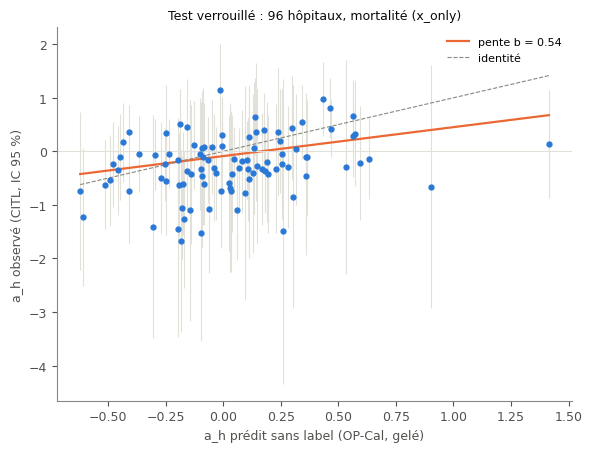

Écrit : ..\results\07_confirmation\rapport_07.md | resultats_confirmatoires.json | journal_07.json | figures/confirmation_opcal.png


In [13]:
# ============================================================
# ÉTAPE 7 — CONTRÔLES, FIGURE ET RAPPORT
# ============================================================
oc.check("Pli final : 60 hôpitaux de développement à l'entraînement, 96 verrouillés en prédiction",
         sorted(P_VAL["hospitalid"].unique()) == DEV and sorted(P_LOCK["x_only"]["hospitalid"].unique()) == LOCKED, CONTROLES)
oc.check("Prédictions finales : chaque séjour verrouillé prédit par toutes les seeds",
         all((P_LOCK[m]["n_seeds"] == len(SEEDS_M)).all() for m in ("x_only", "grud")) and (P_LOCK["lactate"]["n_seeds"] == len(SEEDS_L)).all(), CONTROLES)
oc.check("Fichiers d'entraînement : aucun label verrouillé (marqueur y = −1 pour le rôle transfer)",
         all((pd.read_parquet(pred_path(m, s)).query("role == 'transfer'")["y"] == -1).all() for m in ("x_only", "grud") for s in SEEDS_M), CONTROLES)
eng_events = [e for e in JOURNAL if e["evenement"].startswith("prédictions gelées")]
open_events = [e for e in JOURNAL if e["evenement"].startswith("ouverture")]
oc.check("Prédictions gelées et empreintes enregistrées avant l'ouverture des labels",
         bool(eng_events) and bool(open_events) and eng_events[0]["date"] <= open_events[0]["date"], CONTROLES)
oc.check("Empreintes des prédictions gelées inchangées depuis la phase A", RES["engagement_sha256"] == ENG, CONTROLES)
oc.check("Une seule ouverture des labels", len(open_events) == 1, CONTROLES)
oc.check("τ² de C4 identique à l'amendement", abs(TAU2_MECH - TAU2_TEXT) < 1e-4, CONTROLES)
CONTROLES_DF = pd.DataFrame(CONTROLES)
print(f"\n{int(CONTROLES_DF['ok'].sum())}/{len(CONTROLES_DF)} contrôles réussis")

import matplotlib.pyplot as plt
PAL = {"s1": "#2a78d6", "s2": "#eb6834", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": PAL["muted"],
                     "axes.labelcolor": PAL["ink2"], "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "font.size": 9})
fig, ax = plt.subplots(figsize=(6, 4.6))
a_ = ahat.reindex(calx.index)
ax.errorbar(a_, calx["citl"], yerr=1.96 * np.sqrt(calx["var_citl"]), fmt="o", ms=3.5, color=PAL["s1"], ecolor=PAL["grid"], elinewidth=0.8)
xs = np.linspace(a_.min(), a_.max(), 50)
ax.plot(xs, c1r["alpha"] + c1r["b"] * (xs - a_.mean()), color=PAL["s2"], lw=1.6, label=f"pente b = {c1r['b']:.2f}")
ax.plot(xs, xs, color=PAL["muted"], lw=0.8, ls="--", label="identité")
ax.axhline(0, color=PAL["grid"], lw=0.8)
ax.set_xlabel("a_h prédit sans label (OP-Cal, gelé)"); ax.set_ylabel("a_h observé (CITL, IC 95 %)")
ax.set_title(f"Test verrouillé : {len(calx)} hôpitaux, mortalité (x_only)", fontsize=9, color=PAL["ink"])
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "confirmation_opcal.png", dpi=200); plt.show()

def md_table(df, digits=3):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    esc = lambda x: str(x).replace("|", "\\|")
    head = "| " + " | ".join([esc(df.index.name or "")] + [esc(c) for c in df.columns]) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " | ".join([esc(i)] + [esc(v) for v in row]) + " |" for i, row in zip(df.index, df.to_numpy())]
    return "\n".join([head, sep] + body)

eff = RES["effectifs"]
rapport = f"""# Rapport 07 — confirmation d'OP-Cal sur le test verrouillé

Généré le {datetime.now():%Y-%m-%d %H:%M} par `notebooks/07_confirmation.ipynb`. Protocole `{protocol['hash']}`. Agrégats uniquement.
Spécification `{SPEC_SHA[:16]}…`, amendement 1 `{AMEND_SHA[:16]}…` (validé). Évaluation du {RES['date']}.

{eff['hopitaux']} hôpitaux verrouillés ; mortalité : {eff['sejours_mortalite']} séjours, {eff['deces']} décès ; hyperlactatémie : {eff['sejours_lactate']} séjours, {eff['evenements_lactate']} événements.

## Critères confirmatoires (procédure graphique, unilatéral 2,5 %)

{md_table(TAB_CONF)}

* C1 : b = {c1r['b']:.3f} [{c1r['b_IC_bas']:.3f} ; {c1r['b_IC_haut']:.3f}] (Knapp-Hartung, {c1r['df']} ddl) ; α = {c1r['alpha']:.3f} ; R²_τ = {c1r['R2_tau']:.3f} [{r2_lo:.3f} ; {r2_hi:.3f}] ; bootstrap de b [{np.quantile(bs_b, .025):.3f} ; {np.quantile(bs_b, .975):.3f}].
* C2 : gain de log-vraisemblance par patient contre E0 = {RES['C2']['gain_par_patient']:.5f} [{RES['C2']['IC_bas']:.5f} ; {RES['C2']['IC_haut']:.5f}].
* C4 : γ = {G_EST['gamma']:.3f} [{G_EST['IC_bas']:.3f} ; {G_EST['IC_haut']:.3f}] ; l'IC contient 1 : {G_EST['IC_contient_1']}.

**Conclusions (formulation fixée par l'amendement 1) :**

{chr(10).join('* ' + c for c in RES['conclusions'])}

## Descriptif — comparateurs (mortalité, x_only)

{md_table(TAB_COMP, 4)}

GRU-D (S1) : b = {c1g['b']:.3f} [{c1g['b_IC_bas']:.3f} ; {c1g['b_IC_haut']:.3f}] ; R²_τ = {c1g['R2_tau']:.3f}.
Lactate, terme mécanistique seul : |CITL| {ev_mech['mean_abs_citl']:.3f} (sans correction {ev_e0l['mean_abs_citl']:.3f}) ; R²_τ = {ev_mech['R2_tau']:.3f}.

C3 (k = {K_CONF}, descriptif) :

{md_table(TAB_C3.rename_axis('méthode'))}

Discrimination :

{md_table(AUC, 4)}

## Note d'implémentation (avant l'ouverture des labels)

`site_descriptors` (gelé) ne crée que les colonnes des 6 types d'unité les plus fréquents parmi les hôpitaux qu'on lui passe. Pour les hôpitaux
verrouillés, les colonnes absentes ({', '.join(UNIT_MISSING) or 'aucune'}) ont été calculées par leur nom, avec la même règle et le même
dénominateur. Le calcul est contrôlé sur le développement (identique au 06b). Cette correction a été faite en phase A, avant l'ouverture des labels (journal_07.json).

## Contrôles

{md_table(CONTROLES_DF.set_index('controle'))}
"""
(RES_DIR / "rapport_07.md").write_text(rapport, encoding="utf-8")
journal("rapport écrit")
print(f"Écrit : {RES_DIR / 'rapport_07.md'} | resultats_confirmatoires.json | journal_07.json | figures/confirmation_opcal.png")